In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


plt.rcParams["figure.figsize"] = (8,5)

In [14]:
df = pd.read_csv("mumbai_cab_fare_train.csv")

In [15]:
print("Shape of Dataset:")
print(df.shape)

Shape of Dataset:
(5000, 11)


In [16]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude', 'passenger_count', 'route_distance_km', 'route_duration_min', 'pickup_hour', 'day_of_week', 'weather_flag', 'fare_amount']


In [17]:
print("First 5 Records:")
display(df.head())

First 5 Records:


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,passenger_count,route_distance_km,route_duration_min,pickup_hour,day_of_week,weather_flag,fare_amount
0,19.101462,72.852937,19.130346,72.894241,1,5.40,24.2,10,2,0,221.82
1,19.064299,72.833966,19.209949,72.982574,1,22.49,68.3,15,6,1,662.17
2,19.013098,72.867129,19.200158,72.982402,1,24.07,81.2,6,1,2,909.53
3,19.048836,72.819141,19.094000,72.878928,1,8.04,22.9,16,3,1,225.33
4,19.108018,72.849108,18.954805,72.840980,3,17.06,57.2,13,6,0,489.22


In [18]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   pickup_latitude     5000 non-null   float64
 1   pickup_longitude    5000 non-null   float64
 2   dropoff_latitude    5000 non-null   float64
 3   dropoff_longitude   5000 non-null   float64
 4   passenger_count     5000 non-null   int64  
 5   route_distance_km   5000 non-null   float64
 6   route_duration_min  5000 non-null   float64
 7   pickup_hour         5000 non-null   int64  
 8   day_of_week         5000 non-null   int64  
 9   weather_flag        5000 non-null   int64  
 10  fare_amount         5000 non-null   float64
dtypes: float64(7), int64(4)
memory usage: 429.8 KB


In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_latitude,5000.0,19.063658,0.079914,18.920020,19.014604,19.072451,19.111874,19.237981
pickup_longitude,5000.0,72.878523,0.059779,72.803430,72.835679,72.855651,72.904494,73.018488
dropoff_latitude,5000.0,19.067188,0.080656,18.920086,19.019487,19.074105,19.113981,19.238260
dropoff_longitude,5000.0,72.881020,0.060983,72.803410,72.836372,72.857405,72.908872,73.018571
passenger_count,5000.0,1.606200,0.857945,1.000000,1.000000,1.000000,2.000000,4.000000
route_distance_km,5000.0,13.104770,8.206966,0.510000,6.200000,12.730000,18.540000,38.550000
route_duration_min,5000.0,43.789240,29.286281,1.400000,20.075000,40.300000,61.700000,170.600000
pickup_hour,5000.0,11.589800,6.913197,0.000000,6.000000,12.000000,18.000000,23.000000
day_of_week,5000.0,3.056600,1.998849,0.000000,1.000000,3.000000,5.000000,6.000000
weather_flag,5000.0,0.299200,0.551852,0.000000,0.000000,0.000000,1.000000,2.000000


In [20]:
print("Missing Values in Each Column")
print("-" * 40)

missing = df.isnull().sum()
display(missing)

print(f"\nTotal Missing Values: {missing.sum()}")

Missing Values in Each Column
----------------------------------------


pickup_latitude       0
pickup_longitude      0
dropoff_latitude      0
dropoff_longitude     0
passenger_count       0
route_distance_km     0
route_duration_min    0
pickup_hour           0
day_of_week           0
weather_flag          0
fare_amount           0
dtype: int64


Total Missing Values: 0


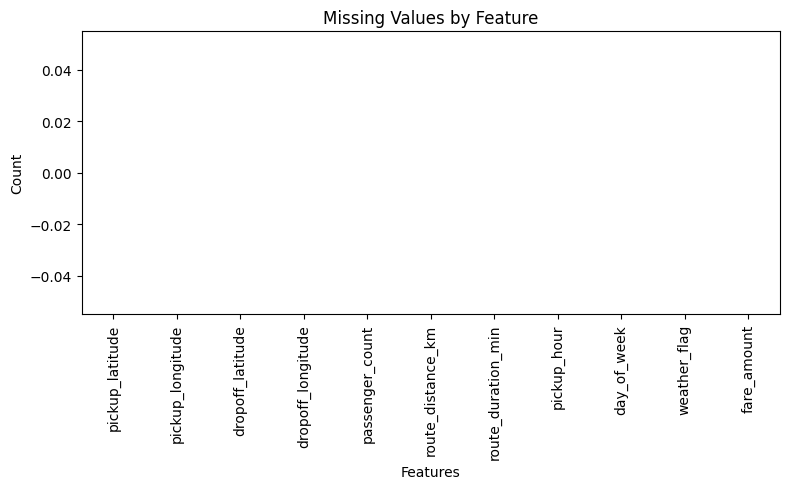

In [21]:
missing.plot(kind="bar")

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Count")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [22]:
duplicates = df.duplicated().sum()

print(f"Duplicate Records: {duplicates}")

if duplicates == 0:
    print("Dataset contains no duplicate rows.")
else:
    print("Duplicate rows should be removed.")

Duplicate Records: 0
Dataset contains no duplicate rows.


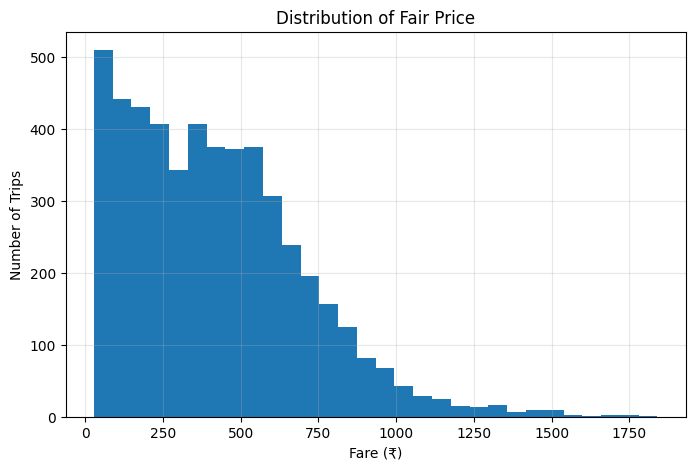

In [27]:
plt.hist(df["fare_amount"], bins=30)

plt.title("Distribution of Fair Price")
plt.xlabel("Fare (₹)")
plt.ylabel("Number of Trips")

plt.grid(alpha=0.3)
plt.show()

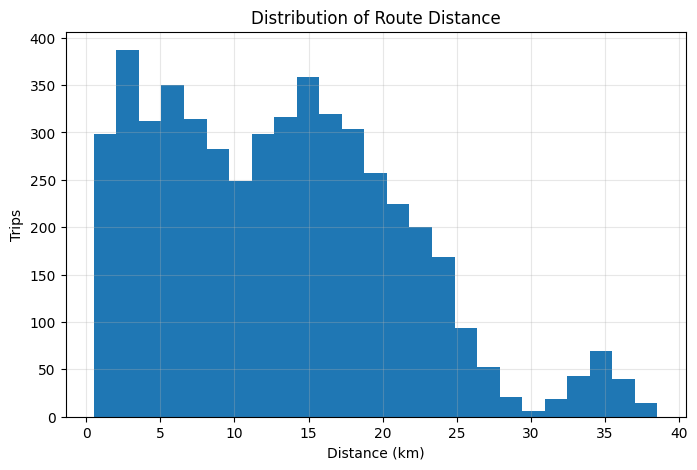

In [29]:
plt.hist(df["route_distance_km"], bins=25)

plt.title("Distribution of Route Distance")
plt.xlabel("Distance (km)")
plt.ylabel("Trips")

plt.grid(alpha=0.3)
plt.show()

In [30]:
summary = pd.DataFrame({
    "Metric": [
        "Average Fare",
        "Average Distance",
        "Average Duration"
    ],
    "Value": [
        round(df["fare_amount"].mean(),2),
        round(df["route_distance_km"].mean(),2),
        round(df["route_duration_min"].mean(),2)
    ]
})

display(summary)

,Metric,Value
0,Average Fare,420.18
1,Average Distance,13.10
2,Average Duration,43.79


In [31]:
correlation = df.corr(numeric_only=True)

correlation

,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,passenger_count,route_distance_km,route_duration_min,pickup_hour,day_of_week,weather_flag,fare_amount
pickup_latitude,1.000000,0.619718,0.001387,0.011235,-0.013475,0.010467,0.002314,0.002790,-0.014764,-0.000853,0.001289
pickup_longitude,0.619718,1.000000,0.014804,0.010417,-0.025798,0.188592,0.167898,-0.006474,-0.022868,-0.009317,0.164234
dropoff_latitude,0.001387,0.014804,1.000000,0.627852,-0.009991,0.072716,0.077510,0.026751,0.000819,0.010242,0.075968
dropoff_longitude,0.011235,0.010417,0.627852,1.000000,-0.021201,0.241627,0.237094,0.010145,0.008722,0.010201,0.236448
passenger_count,-0.013475,-0.025798,-0.009991,-0.021201,1.000000,-0.011391,-0.011955,0.004294,-0.012779,-0.002905,-0.009910
route_distance_km,0.010467,0.188592,0.072716,0.241627,-0.011391,1.000000,0.940634,0.026698,0.005272,-0.012396,0.935207
route_duration_min,0.002314,0.167898,0.077510,0.237094,-0.011955,0.940634,1.000000,0.125286,0.005441,-0.015228,0.982198
pickup_hour,0.002790,-0.006474,0.026751,0.010145,0.004294,0.026698,0.125286,1.000000,0.016678,-0.008827,0.072121
day_of_week,-0.014764,-0.022868,0.000819,0.008722,-0.012779,0.005272,0.005441,0.016678,1.000000,-0.005381,0.003884
weather_flag,-0.000853,-0.009317,0.010242,0.010201,-0.002905,-0.012396,-0.015228,-0.008827,-0.005381,1.000000,0.100390


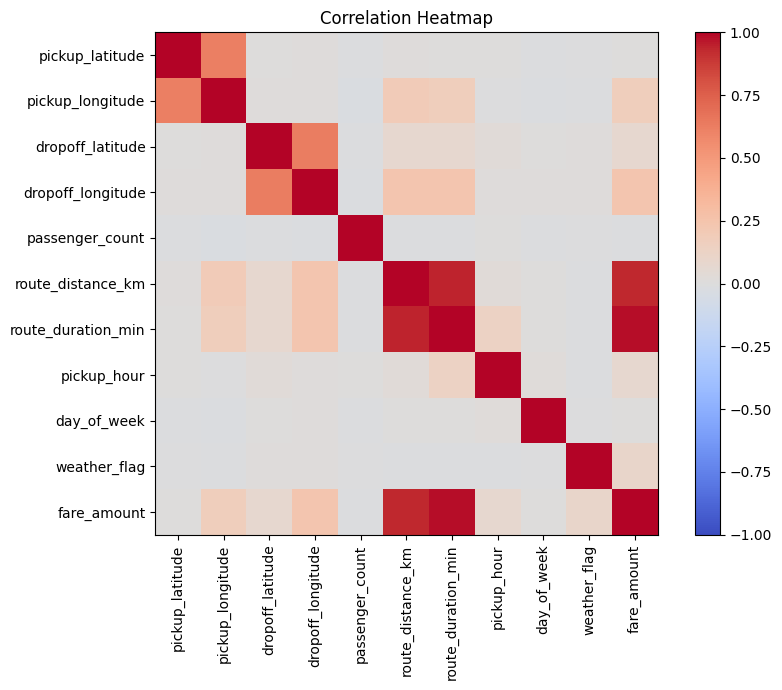

In [32]:
fig, ax = plt.subplots(figsize=(9,7))

heatmap = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90)

ax.set_yticks(range(len(correlation.columns)))
ax.set_yticklabels(correlation.columns)

plt.colorbar(heatmap)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [33]:
fare_corr = correlation["fare_amount"].sort_values(ascending=False)

print("Correlation with Fare Amount")
display(fare_corr)

Correlation with Fare Amount


fare_amount           1.000000
route_duration_min    0.982198
route_distance_km     0.935207
dropoff_longitude     0.236448
pickup_longitude      0.164234
weather_flag          0.100390
dropoff_latitude      0.075968
pickup_hour           0.072121
day_of_week           0.003884
pickup_latitude       0.001289
passenger_count      -0.009910
Name: fare_amount, dtype: float64

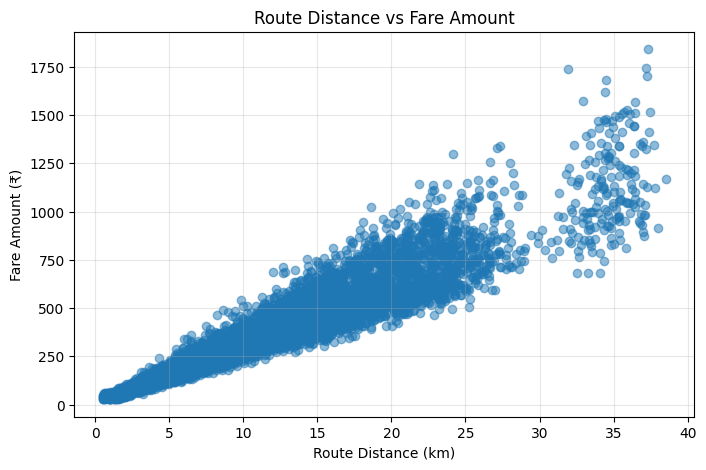

In [34]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["route_distance_km"],
    df["fare_amount"],
    alpha=0.5
)

plt.title("Route Distance vs Fare Amount")
plt.xlabel("Route Distance (km)")
plt.ylabel("Fare Amount (₹)")

plt.grid(alpha=0.3)
plt.show()

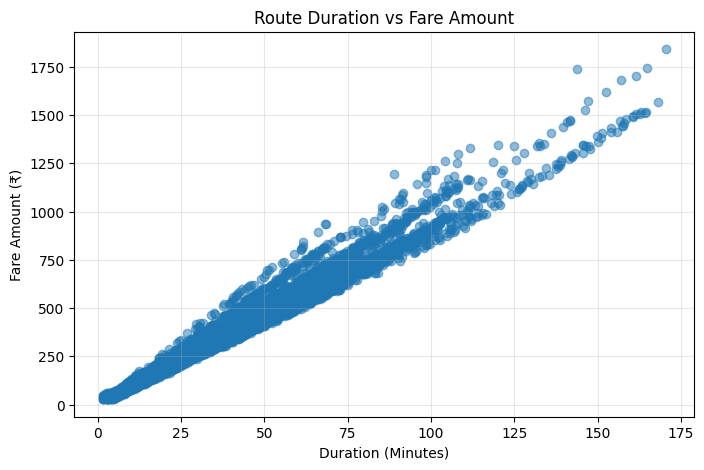

In [35]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["route_duration_min"],
    df["fare_amount"],
    alpha=0.5
)

plt.title("Route Duration vs Fare Amount")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Fare Amount (₹)")

plt.grid(alpha=0.3)
plt.show()

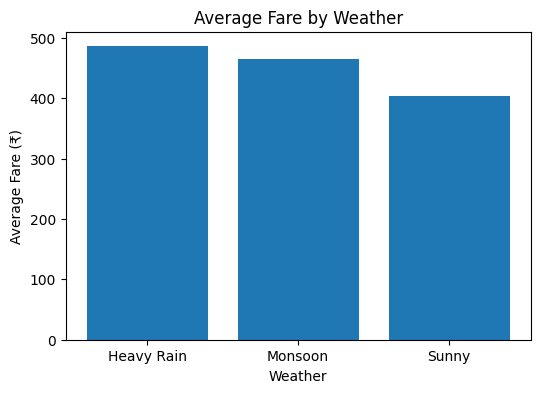

weather_name
Heavy Rain    486.151139
Monsoon       465.761448
Sunny         403.549201
Name: fare_amount, dtype: float64

In [36]:
weather_map = {
    0: "Sunny",
    1: "Monsoon",
    2: "Heavy Rain"
}

df["weather_name"] = df["weather_flag"].map(weather_map)

avg_weather = df.groupby("weather_name")["fare_amount"].mean()

plt.figure(figsize=(6,4))

plt.bar(avg_weather.index, avg_weather.values)

plt.title("Average Fare by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Fare (₹)")

plt.show()

display(avg_weather)

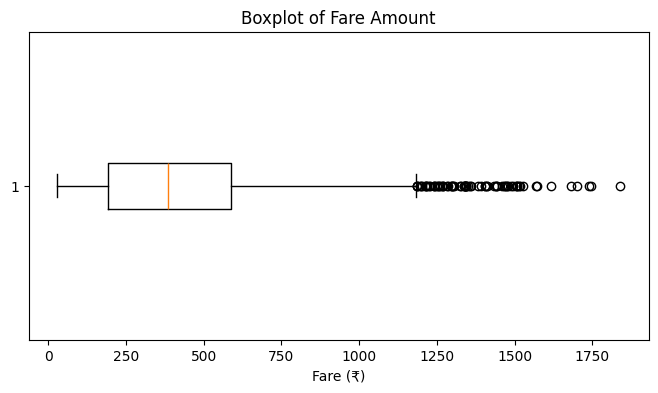

In [37]:
plt.figure(figsize=(8,4))

plt.boxplot(df["fare_amount"], vert=False)

plt.title("Boxplot of Fare Amount")
plt.xlabel("Fare (₹)")

plt.show()

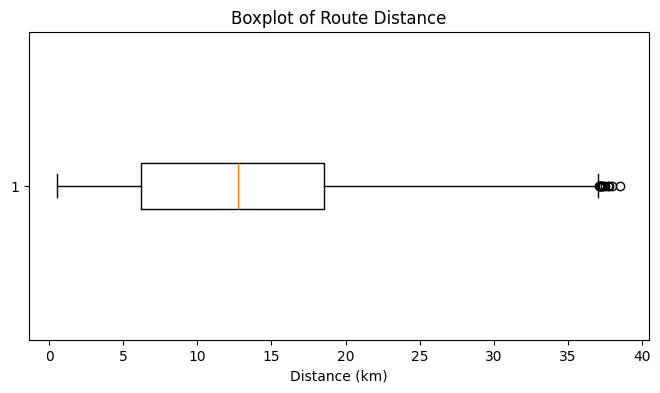

In [38]:
plt.figure(figsize=(8,4))

plt.boxplot(df["route_distance_km"], vert=False)

plt.title("Boxplot of Route Distance")
plt.xlabel("Distance (km)")

plt.show()

In [39]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("Total Outliers:", len(outliers))

outliers.head()

Total Outliers: 74


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,passenger_count,route_distance_km,route_duration_min,pickup_hour,day_of_week,weather_flag,fare_amount,weather_name
96,19.211755,72.979001,18.929551,72.819719,1,35.57,153.9,17,3,0,1412.44,Sunny
114,18.942998,72.827401,19.232705,72.989294,1,36.43,133.3,21,2,0,1185.16,Sunny
151,19.211201,72.959016,18.932745,72.841693,1,33.33,139.1,9,0,0,1267.90,Sunny
160,19.225825,72.975604,18.953635,72.816837,3,34.56,146.6,20,3,0,1337.70,Sunny
239,19.217339,72.962539,19.012593,72.829894,2,26.69,118.6,17,4,1,1258.55,Monsoon
